# 13b. 강건성 점검 CV 재점검 (13 리뷰 후속)

## 배경
- 13에서 검증 fold에 가짜 승객 변이를 넣었더니 **LR은 잘 버티고 XGB는 크게 떨어짐** → 그런데 실제 LB는 XGB가 이김 → H13 기각
- 13 리뷰에서 나온 두 가지 의문
  1. **교란**: 05 LR에는 stats(변이 개수 피처)가 없고 XGB 3개는 모두 stats를 씀 → XGB가 떨어진 게 **트리 구조 때문인지, stats가 가짜 변이에 흔들려서인지** 구분이 안 됨
  2. **가짜 변이 유형**: 13은 가짜 변이를 모두 미스센스로 넣음 → 침묵 비율(silent_ratio)이 한쪽으로만 바뀌어 stats 모델에 더 불리할 수 있음

## 질문
- Q1: stats를 뺀 XGB(10 설정, any만)도 크게 떨어지는가? → 떨어지면 트리 구조 문제, 안 떨어지면 stats 문제
- Q2: 가짜 변이를 **실제 유형 비율**(침묵 26.5% 등)로 넣으면 13의 결론이 바뀌는가?
- Q3: 어느 방식이든 가짜 변이 점수가 LB 순서를 맞히는가? (13 결론 재확인, 이번엔 LB 아는 모델 7개)

## 검증 방법
- 모델 8개: LB를 아는 7개(LR 05 / 07 F / 07 E, XGB 09 / 10 / 11 / 12-k20) + **대조군 XGB_10_nostats**(미제출)
- 학습은 원래 데이터(fold 학습 부분), **검증 fold에만** 가짜 변이 추가 후 다시 채점
- 가짜 변이: 환자마다 Poisson(비율 × 원래 변이 유전자 수)개, 유전자는 **fold 학습 부분** 빈도에 비례해 선택
  - **mixed**: 변이 유형을 fold 학습 부분 비율대로 (침묵 26.5% / 미스센스 64.5% / nonsense 5% / frameshift 4%)
  - **missense**: 전부 미스센스 (13 방식)
  - 두 방식은 같은 난수를 써서 **고른 유전자는 같고 유형만 다름** → 유형 효과만 비교
- 원본 문자열에 가짜 변이를 넣은 뒤 **피처를 처음부터 다시 계산** → stats, trunc, 핫스팟이 모두 자연스럽게 반영
- 비율 0(원래 CV) / 0.5 / 1.0 / 2.0 (13과 같음), 무작위 시드 2개 평균

## 누수 여부
- 가짜 변이에 쓰는 통계(유전자 빈도, 유형 비율)는 fold 학습 부분으로만 계산, test는 사용하지 않음
- LB는 이미 제출한 결과를 비교용으로만 사용 (이 결과로 모델이나 피처를 고르지 않음)

#### 준비: 데이터, 공통 분할

In [1]:
import sys; sys.path.append('..')
import time, numpy as np, pandas as pd, xgboost as xgb
from collections import Counter
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from src.config import SEED, WT
from src.data import load_data, get_gene_cols
from src.features import mutation_features, mutation_type, MUT_TYPES
from src.validation import seed_everything, encode_target, get_folds, macro_f1

seed_everything()
train, test, submission = load_data()
genes = get_gene_cols(train)
y, le = encode_target(train)
folds = get_folds(y)
STAT_COLS = None  # set after features built

#### 피처: 각 노트북과 같은 조합
- `build_features()`: 원본 문자열 → 모델들이 쓰는 피처 세트를 한 번에 만듦. 가짜 변이를 넣은 검증 데이터도 같은 함수로 다시 계산
- 핫스팟 후보는 11과 같은 방식 (전체 train 5명 이상 후보, 실제 선택은 Pipeline 안에서 fold마다)

In [2]:
def patient_tokens(df):
    out = []
    for row in df[genes].to_numpy():
        s = set()
        for g, v in zip(genes, row):
            if v != WT:
                s.update(f'{g}_{t}' for t in v.split())
        out.append(s)
    return out

cnt = Counter(t for s in patient_tokens(train) for t in s)
VOCAB = sorted(t for t, n in cnt.items() if n >= 5)     # 11과 동일 (후보 목록, 선택은 fold 안에서)
def safe(name):
    return 'hs__' + name.replace('*', 'stop').replace('>', '_to_')
HS_COLS = [safe(t) for t in VOCAB]

def hotspot_matrix(df):
    col = {t: j for j, t in enumerate(VOCAB)}
    M = np.zeros((len(df), len(VOCAB)), np.int8)
    for i, s in enumerate(patient_tokens(df)):
        for t in s:
            if t in col: M[i, col[t]] = 1
    return pd.DataFrame(M, index=df.index, columns=HS_COLS)

def build_features(df):
    """원본 문자열 → 모델들이 쓰는 피처 세트 (모두 한 행 안에서 계산)"""
    F = mutation_features(df, genes)
    return {
        'any': F['any'],
        'any+trunc': pd.concat([F['any'], F['trunc']], axis=1),
        'any+trunc+stats': pd.concat([F['any'], F['trunc'], F['stats']], axis=1),
        'any+stats': pd.concat([F['any'], F['stats']], axis=1),
        'any+stats+hs': pd.concat([F['any'], F['stats'], hotspot_matrix(df)], axis=1),
    }

#### 모델 8개
| 이름 | 피처 | 설정 | 실제 LB |
| :--- | :--- | :--- | :-: |
| LR_05 | any | C=0.1, balanced | 0.2739 |
| LR_07F | any + trunc | C=0.1, balanced | 0.2700 |
| LR_07E | any + trunc + stats | C=0.1, balanced, stats 표준화 | 0.2706 |
| XGB_09 | any + stats | depth 6, 100그루 | 0.2995 |
| XGB_10 | any + stats | depth 3, 200그루, colsample 0.3 | 0.3206 |
| **XGB_10_nostats** | **any** | **10과 같은 설정 (대조군)** | 미제출 |
| XGB_11 | any + stats + 핫스팟 | 10 설정 + 핫스팟 min10 | 0.3166 |
| XGB_12k20 | any + stats | 10 설정 + 희귀 유전자(20명 미만) 제거 | 0.3051 |

- XGB_10과 XGB_10_nostats는 stats 유무만 다름 → Q1 비교용

In [3]:
class BalancedXGB(xgb.XGBClassifier):
    def fit(self, X, y, **kw):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y), **kw)

class FrequentTokens(BaseEstimator, TransformerMixin):
    def __init__(self, min_count=10):
        self.min_count = min_count
    def fit(self, X, y=None):
        hs = [c for c in X.columns if c.startswith('hs__')]
        n = X[hs].sum()
        self.drop_ = n.index[n < self.min_count].tolist()
        return self
    def transform(self, X):
        return X.drop(columns=self.drop_)

class RareGeneFilter(BaseEstimator, TransformerMixin):
    """12와 동일: fold 학습 부분에서 변이 환자가 min_count명 미만인 유전자 열 제거"""
    def __init__(self, gene_cols, min_count=5):
        self.gene_cols, self.min_count = gene_cols, min_count
    def fit(self, X, y=None):
        n = X[self.gene_cols].sum()
        self.drop_ = n.index[n < self.min_count].tolist()
        return self
    def transform(self, X):
        return X.drop(columns=self.drop_)

XGB_BASE = dict(tree_method='hist', eval_metric='mlogloss', random_state=SEED, n_jobs=-1)
BEST10 = dict(max_depth=3, learning_rate=0.1, n_estimators=200, colsample_bytree=0.3)
STAT_NAMES = [f'n_{t}_log' for t in MUT_TYPES] + ['n_gene_log', 'silent_ratio']

def lr(C=0.1):
    return LogisticRegression(C=C, max_iter=3000, class_weight='balanced', random_state=SEED)

MODELS = {
    # 이름: (피처 세트, 모델 생성 함수, 실제 LB)
    'LR_05':        ('any', lambda: lr(0.1), 0.2739),
    'LR_07F':       ('any+trunc', lambda: lr(0.1), 0.2700),
    'LR_07E':       ('any+trunc+stats', lambda: make_pipeline(
                        ColumnTransformer([('sc', StandardScaler(), STAT_NAMES)], remainder='passthrough'), lr(0.1)), 0.2706),
    'XGB_09':       ('any+stats', lambda: BalancedXGB(**XGB_BASE, max_depth=6, learning_rate=0.1, n_estimators=100), 0.2995),
    'XGB_10':       ('any+stats', lambda: BalancedXGB(**XGB_BASE, **BEST10), 0.3206),
    'XGB_10_nostats': ('any', lambda: BalancedXGB(**XGB_BASE, **BEST10), None),   # 대조군 (미제출)
    'XGB_11':       ('any+stats+hs', lambda: make_pipeline(FrequentTokens(10), BalancedXGB(**XGB_BASE, **BEST10)), 0.3166),
    'XGB_12k20':    ('any+stats', lambda: make_pipeline(RareGeneFilter(genes, 20), BalancedXGB(**XGB_BASE, **BEST10)), 0.3051),
}

#### 가짜 승객 변이 넣기
- `background_from()`: fold 학습 부분으로만 유전자 빈도와 유형 비율 계산
- `add_passengers()`: 원본 문자열에 가짜 변이 추가 (WT면 바꾸고, 이미 변이가 있으면 공백으로 덧붙임). `mode='missense'`면 유형만 전부 미스센스로

In [4]:
FAKE_TOKEN = {'silent': 'A{}A', 'missense': 'A{}V', 'nonsense': 'A{}*', 'frameshift': 'A{}fs'}

def background_from(df_tr):
    """학습 fold로만 계산: 유전자별 변이 빈도(+1), 변이 유형 비율"""
    V = df_tr[genes].to_numpy()
    gene_p = (V != WT).sum(axis=0) + 1.0
    gene_p = gene_p / gene_p.sum()
    types = Counter(mutation_type(t) for v in V[V != WT] for t in v.split())
    keep = [t for t in FAKE_TOKEN]
    type_p = np.array([types[t] for t in keep], float); type_p /= type_p.sum()
    return gene_p, keep, type_p

def add_passengers(df_va, rate, gene_p, keep, type_p, seed, mode='mixed'):
    """검증 환자마다 (자기 변이 유전자 수 × rate)개 정도의 가짜 변이를 무작위 유전자에 추가"""
    rng = np.random.default_rng(seed)
    if mode == 'missense':                       # 13 방식: 가짜 변이를 모두 미스센스로
        type_p = np.array([1.0 if t == 'missense' else 0.0 for t in keep])
    V = df_va[genes].to_numpy().copy()
    n_mut = (V != WT).sum(axis=1)
    k = rng.poisson(rate * np.maximum(n_mut, 1))
    for i in range(len(V)):
        if k[i] == 0: continue
        cols = rng.choice(len(genes), size=min(k[i], len(genes)), replace=False, p=gene_p)
        kinds = rng.choice(len(keep), size=len(cols), p=type_p)
        for j, kd in zip(cols, kinds):
            tok = FAKE_TOKEN[keep[kd]].format(rng.integers(1, 2000))
            V[i, j] = tok if V[i, j] == WT else V[i, j] + ' ' + tok
    out = df_va.copy()
    out[genes] = V
    return out, k

#### 실행: fold마다 한 번 학습 → 원래 검증 + 가짜 변이 검증 12가지(유형 2 × 비율 3 × 시드 2)로 채점
- 모든 모델이 같은 가짜 변이 검증셋을 사용 → 공정한 비교
- 2코어 기준 약 35분

In [5]:
MODES, RATES, NOISE_SEEDS = ['mixed', 'missense'], [0.5, 1.0, 2.0], [0, 1]
FT = build_features(train)
rows = []
t0 = time.time()
for f, (tr, va) in enumerate(folds):
    gene_p, keep, type_p = background_from(train.iloc[tr])
    noisy = {}
    for mode in MODES:
        for rate in RATES:
            for s in NOISE_SEEDS:
                df_noisy, _ = add_passengers(train.iloc[va], rate, gene_p, keep, type_p,
                                             seed=SEED + 100 * f + 10 * RATES.index(rate) + s, mode=mode)
                noisy[(mode, rate, s)] = build_features(df_noisy)
    for name, (fs, make, lb) in MODELS.items():
        m = make()
        m.fit(FT[fs].iloc[tr], y[tr])
        clean = macro_f1(y[va], m.predict_proba(FT[fs].iloc[va]).argmax(1))
        for mode in MODES:
            rows.append(dict(model=name, mode=mode, fold=f, rate=0.0, seed=0, f1=clean))
        for (mode, rate, s), FN in noisy.items():
            rows.append(dict(model=name, mode=mode, fold=f, rate=rate, seed=s,
                             f1=macro_f1(y[va], m.predict_proba(FN[fs]).argmax(1))))
    print(f'fold {f} 완료 ({time.time() - t0:.0f}s)')
res = pd.DataFrame(rows)

fold 0 완료 (379s)


fold 1 완료 (760s)


fold 2 완료 (1139s)


fold 3 완료 (1524s)


fold 4 완료 (1917s)


#### 결과 1: 비율별 점수 (5-Fold 평균, 시드 평균)

In [6]:
LB = pd.Series({k: v[2] for k, v in MODELS.items()}, dtype=float)
cols = {0.0: 'x0 (CV)', 0.5: 'x0.5', 1.0: 'x1.0', 2.0: 'x2.0'}
def table(mode):
    t = (res[res['mode'] == mode].groupby(['model', 'rate']).f1.mean().unstack()
         .rename(columns=cols).loc[list(MODELS)])
    t['유지율(x1.0)'] = t['x1.0'] / t['x0 (CV)']
    t['LB'] = LB
    return t
T = {mode: table(mode) for mode in MODES}
for mode in MODES:
    print(f'===== {mode} =====')
    print(T[mode].round(4).to_string(), '\n')

===== mixed =====
rate            x0 (CV)    x0.5    x1.0    x2.0  유지율(x1.0)      LB
model                                                             
LR_05            0.3818  0.3477  0.3154  0.2726     0.8261  0.2739
LR_07F           0.3920  0.3607  0.3377  0.2929     0.8614  0.2700
LR_07E           0.4187  0.3636  0.3199  0.2486     0.7640  0.2706
XGB_09           0.3879  0.3313  0.2741  0.1895     0.7067  0.2995
XGB_10           0.4105  0.3492  0.2889  0.2093     0.7037  0.3206
XGB_10_nostats   0.3569  0.3222  0.3031  0.2623     0.8492     NaN
XGB_11           0.4213  0.3644  0.3079  0.2328     0.7307  0.3166
XGB_12k20        0.4086  0.3440  0.2830  0.2022     0.6926  0.3051 

===== missense =====
rate            x0 (CV)    x0.5    x1.0    x2.0  유지율(x1.0)      LB
model                                                             
LR_05            0.3818  0.3477  0.3154  0.2726     0.8261  0.2739
LR_07F           0.3920  0.3630  0.3376  0.2935     0.8611  0.2700
LR_07E           0.41

#### Q1: XGB의 하락은 stats 때문인가 (x1.0 기준 유지율)
- 유지율 = 가짜 변이 x1.0 점수 / 원래 CV. 1에 가까울수록 잘 버팀

In [7]:
q1 = pd.DataFrame({mode: T[mode]['유지율(x1.0)'] for mode in MODES}).loc[
    ['LR_05', 'LR_07E', 'XGB_10_nostats', 'XGB_10', 'XGB_09']].round(3)
q1.columns = ['유지율 mixed', '유지율 missense']
q1

,유지율 mixed,유지율 missense
model,,
LR_05,0.826,0.826
LR_07E,0.764,0.802
XGB_10_nostats,0.849,0.849
XGB_10,0.704,0.722
XGB_09,0.707,0.661


#### Q2·Q3: LB 순서를 맞히는가 (LB 아는 7개 모델)
- Spearman: 1이면 LB 순서와 같음, 음수면 반대. **모델 7개라 우연 변동이 큼** → 그룹 단위(LR 평균 vs XGB 평균)도 같이 봄
- 10 vs 12-k20: 원래 CV로는 구분 못 하는 쌍 (LB는 10이 +0.0155)

In [8]:
from scipy.stats import spearmanr
lb_models = [m for m in MODELS if not np.isnan(LB[m])]
out = []
for mode in MODES:
    for c in ['x0 (CV)', 'x0.5', 'x1.0', 'x2.0']:
        s = T[mode].loc[lb_models, c]
        rho, p = spearmanr(s, LB[lb_models])
        lr_mean = s[[m for m in lb_models if m.startswith('LR')]].mean()
        xgb_mean = s[[m for m in lb_models if m.startswith('XGB')]].mean()
        out.append(dict(mode=mode, 평가=c, spearman=round(rho, 2), p값=round(p, 2),
                        **{'XGB−LR 평균 (LB는 +0.039)': round(xgb_mean - lr_mean, 4),
                           '10−12k20 (LB는 +0.0155)': round(s['XGB_10'] - s['XGB_12k20'], 4)}))
q23 = pd.DataFrame(out)
q23

,mode,평가,spearman,p값,XGB−LR 평균 (LB는 +0.039),10−12k20 (LB는 +0.0155)
0,mixed,x0 (CV),0.39,0.38,0.0096,0.0019
1,mixed,x0.5,-0.07,0.88,-0.0101,0.0053
2,mixed,x1.0,-0.68,0.09,-0.0358,0.0059
3,mixed,x2.0,-0.64,0.12,-0.0629,0.0071
4,missense,x0 (CV),0.39,0.38,0.0096,0.0019
5,missense,x0.5,-0.14,0.76,-0.0118,0.0026
6,missense,x1.0,-0.57,0.18,-0.0388,0.0050
7,missense,x2.0,-0.68,0.09,-0.0630,0.0020


#### 그래프: 가짜 변이 비율에 따른 점수 (발표용)

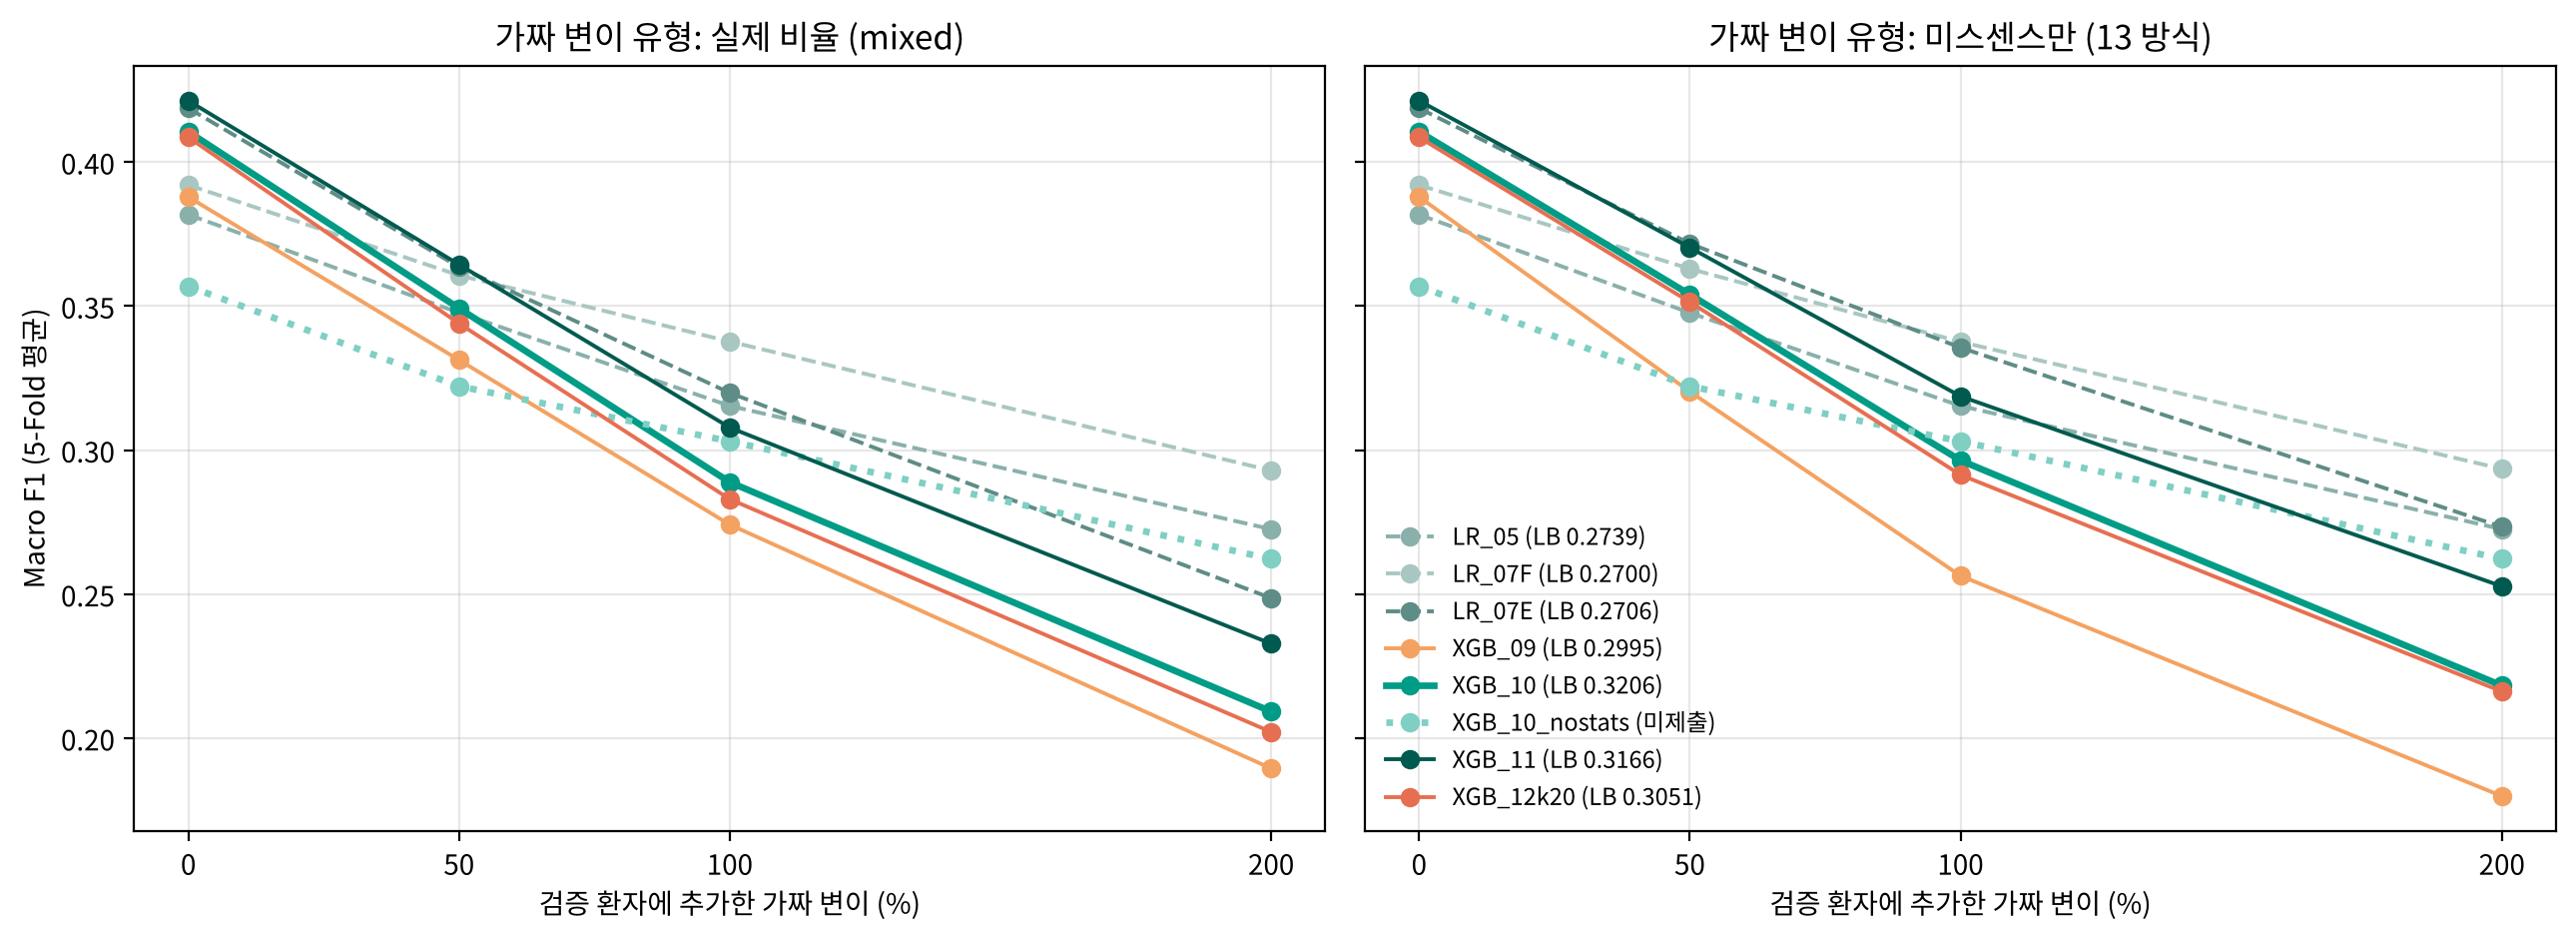

In [9]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
for fname in ['AppleGothic', 'Malgun Gothic', 'Noto Sans CJK JP', 'NanumGothic']:
    if any(fname == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = fname; break
plt.rcParams['axes.unicode_minus'] = False

COLOR = {'LR_05': '#8AB0AB', 'LR_07F': '#A9C7C2', 'LR_07E': '#5E8C86', 'XGB_09': '#F4A261',
         'XGB_10': '#009C86', 'XGB_10_nostats': '#7FCFC3', 'XGB_11': '#005A4F', 'XGB_12k20': '#E76F51'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, mode, title in zip(axes, MODES, ['가짜 변이 유형: 실제 비율 (mixed)', '가짜 변이 유형: 미스센스만 (13 방식)']):
    for name in MODELS:
        ys = T[mode].loc[name, ['x0 (CV)', 'x0.5', 'x1.0', 'x2.0']].values
        lb = '미제출' if np.isnan(LB[name]) else f'LB {LB[name]:.4f}'
        ax.plot([0, 50, 100, 200], ys, marker='o', color=COLOR[name],
                lw=2.4 if name in ('XGB_10', 'XGB_10_nostats') else 1.4,
                ls='--' if name.startswith('LR') else (':' if name == 'XGB_10_nostats' else '-'),
                label=f'{name} ({lb})')
    ax.set_title(title); ax.set_xlabel('검증 환자에 추가한 가짜 변이 (%)'); ax.set_xticks([0, 50, 100, 200]); ax.grid(alpha=0.3)
axes[0].set_ylabel('Macro F1 (5-Fold 평균)')
axes[1].legend(fontsize=8.5, frameon=False, loc='lower left')
plt.tight_layout(); plt.show()

## 결과

**원래 CV 재현**: LR 3개는 기존 값과 같음 (05 0.3818, 07 E 0.4187). XGB는 실행 환경 차이로 ±0.002 (10: 0.4105 vs 0.4113, 11: 0.4213 vs 0.4207)

**Q1. XGB의 하락은 stats 때문인가** (유지율 = x1.0 점수 / 원래 CV)

| 모델 | stats | 유지율 mixed | 유지율 missense |
| :--- | :-: | :-: | :-: |
| LR_05 | 없음 | 0.826 | 0.826 |
| **XGB_10_nostats** | **없음** | **0.849** | **0.849** |
| LR_07E | 있음 | 0.764 | 0.802 |
| XGB_10 | 있음 | 0.704 | 0.722 |
| XGB_09 | 있음 | 0.707 | 0.661 |

- stats를 뺀 XGB가 **LR_05보다도 잘 버팀** → XGB가 약했던 건 트리 구조가 아니라 **stats(변이 개수 피처)** 때문
- LR도 stats가 있는 07 E는 05보다 더 떨어짐 → 모델 종류와 상관없이 stats가 가짜 변이에 흔들림

**Q2. 가짜 변이 유형을 바꾸면 결론이 바뀌는가**
- mixed와 missense의 차이는 모델별로 ±0.04 이내이고 방향이 일정하지 않음 (07 E는 mixed에서 더 떨어지고, 09는 missense에서 더 떨어짐)
- 모델 순위와 결론은 두 방식이 같음 → 13의 "미스센스만" 가정은 결과를 크게 바꾸지 않음

**Q3. LB 순서를 맞히는가** (LB 아는 모델 7개)

| 평가 | Spearman (mixed) | Spearman (missense) | XGB−LR 평균 (LB: +0.039) | 10−12k20 (LB: +0.0155) |
| :--- | :-: | :-: | :-: | :-: |
| 원래 CV | +0.39 | +0.39 | +0.010 | +0.002 |
| x0.5 | −0.07 | −0.14 | −0.010 / −0.012 | +0.005 / +0.003 |
| x1.0 | −0.68 | −0.57 | −0.036 / −0.039 | +0.006 / +0.005 |
| x2.0 | −0.64 | −0.68 | −0.063 / −0.063 | +0.007 / +0.002 |

- 가짜 변이를 넣을수록 LB 순서와 반대 (p값 0.09~0.18, 모델 7개라 통계적으로 확정은 아님)
- 그룹 단위로 보면 분명함: 가짜 변이 점수는 **LR이 XGB보다 낫다**고 하지만 LB는 XGB가 0.039 높음
- 10 vs 12-k20: 방향은 LB와 같게(10이 높게) 나오지만 차이가 0.002~0.007로 작아 판별 기준으로 쓰기는 어려움

## 결론
- **13의 결론(강건성 점수는 LB 순서를 못 맞힘)은 그대로 유지**: 유형을 바꾸고 모델을 7개로 늘려도 같음 → 제출 후보 선택 기준으로 쓰지 않음
- **13의 원인 해석은 수정 필요**: "XGB는 소수 분기에 의존해 잡음에 약하다"가 아니라 **"stats가 있는 모델이 가짜 변이에 약하다"**
  - 같은 XGB 설정에서 stats만 빼면 가장 잘 버팀 (유지율 0.849)
- 이 결과가 test에 대해 말해 주는 것
  - test에 무작위 변이가 많이 늘어난 것이라면, 가짜 변이에 가장 약한 stats 모델(XGB_10)이 LB에서 크게 떨어졌어야 함
  - 실제로는 XGB_10이 LB 최고 → **train과 test의 차이는 "무작위 승객 변이 증가"로 설명되지 않음** (13과 같은 결론을 교란 없이 확인)
- 14(LR + XGB 섞기)의 근거로 "약점이 정반대"를 쓰기는 어려움 → 반대로 보였던 건 stats 유무 차이였음. 섞기는 OOF 기준으로 판단
- XGB_10_nostats는 원래 CV가 0.3569로 낮아 제출 후보는 아님